# Boston 311 Crew Planner

## How we used AI

We used Claude to propose and compare approaches for the key decisions (the forecast method, the optimizer formulation and the intake design) and to help write code. Claude drafted most of the code for setup, the forecast, the staffing model and sensitivity, and the intake assistant, planner agent and app (Sections 0 and 3–8), and the first draft of Section 10 from our report. The data work, exploratory analysis and equity analysis (Sections 1, 2 and 9) are our own code, reviewed with Claude. In every section we chose among the options, reviewed the code, ran it, checked the results against the brief, and fixed what was wrong. The intake test set's labels were drafted with Claude and checked by hand. Inside the app, Groq's gpt-oss models produce the intake assistant's and the planner agent's responses. The assistant suggests a routing; it doesn't replace 311 staff, and its accuracy is measured on our test set in Section 6.

## 0. Setup

In [1]:
import os
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import pulp
from dotenv import load_dotenv
# The import warns that langchain-community is being sunset; we only use its SQLite cache
warnings.filterwarnings("ignore", category=DeprecationWarning, message="`langchain-community` is being sunset")
from langchain_community.cache import SQLiteCache
from langchain_core.globals import set_llm_cache

# Find the repo root so the notebook works whether Jupyter starts in notebooks/ or the repo root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
load_dotenv(ROOT / ".env")

RAW, PROCESSED, CACHE = ROOT / "data/raw", ROOT / "data/processed", ROOT / "data/cache"
for d in (RAW, PROCESSED, CACHE):
    d.mkdir(parents=True, exist_ok=True)

# The brief's facts
DEPTS = {
    "PWDx": {"name": "Public Works", "per_crew_day": 12, "annual_cost": 130_000, "jan_crews": 50},
    "BTDT": {"name": "Transportation", "per_crew_day": 15, "annual_cost": 110_000, "jan_crews": 18},
    "PARK": {"name": "Parks & Recreation", "per_crew_day": 6, "annual_cost": 120_000, "jan_crews": 10},
    "ISD": {"name": "Inspectional Services", "per_crew_day": 4, "annual_cost": 140_000, "jan_crews": 16},
}
WORK_DAYS = 21
RELEASE_FEE = 0.25  # share of annual cost
SEASONAL_MULT = 1.3  # Parks seasonal crews, times monthly cost
SEASONAL_MONTHS = range(4, 11)  # April to October
OVERDUE_PENALTY = 20
LATE_30_PENALTY = 100  # extra, for a request still open 30 days past its target

# Cache reads warn about a future default; set after the imports because langchain installs its own filter on import
warnings.filterwarnings("ignore", message="The default value of `allowed_objects` will change")

LLM_MODEL = os.getenv("LLM_MODEL", "openai/gpt-oss-20b")
set_llm_cache(SQLiteCache(database_path=str(CACHE / "llm_cache.db")))

print(pd.DataFrame({code: {"name": d["name"], "monthly capacity": f"{d['jan_crews'] * d['per_crew_day'] * WORK_DAYS:,}"}
                    for code, d in DEPTS.items()}).T)
print("GROQ_API_KEY set:", bool(os.getenv("GROQ_API_KEY")))
print("LLM_MODEL:", LLM_MODEL)

                       name monthly capacity
PWDx           Public Works           12,600
BTDT         Transportation            5,670
PARK     Parks & Recreation            1,260
ISD   Inspectional Services            1,344
GROQ_API_KEY set: True
LLM_MODEL: openai/gpt-oss-120b


## 1. Data

311 requests opened in 2023 and 2024, from Analyze Boston. `request_types.csv` keeps every department and queue a type was sent to in 2024, across all departments; everything after it uses only the four departments in the brief.

In [2]:
import html
import shutil
import urllib.request

URL = "https://data.boston.gov/dataset/8048697b-ad64-4bfc-b090-ee00169f2323/resource/{}/download/lagan_311_open_data_{}_rvsd3.csv"
FILES = {2023: "e6013a93-1321-4f2a-bf91-8d8a02f1e62f", 2024: "dff4d804-5031-443a-8409-8344efd0e5c8"}

# data.boston.gov redirects to a signed S3 URL with an explicit ":443"; urllib keeps the port in the Host header, which breaks the signature (HTTP 403)
class StripPort(urllib.request.HTTPRedirectHandler):
    def redirect_request(self, req, fp, code, msg, headers, newurl):
        return super().redirect_request(req, fp, code, msg, headers, newurl.replace(":443/", "/"))

for year, resource in FILES.items():
    path = RAW / f"311_{year}.csv"
    if not path.exists():
        with urllib.request.build_opener(StripPort).open(URL.format(resource, year)) as r, open(path, "wb") as f:
            shutil.copyfileobj(r, f)

con = duckdb.connect()
con.sql(f"create view raw as select * from read_csv_auto({[str(RAW / f'311_{y}.csv') for y in FILES]})")
con.sql("select year(open_dt) as year, count(*) as requests from raw group by 1 order by 1").df()

,year,requests
0,2023,307791
1,2024,306756


In [3]:
types = con.sql("""
    select department as dept, type, queue, count(*) as n_2024
    from raw where year(open_dt) = 2024
    group by all order by type, n_2024 desc, dept, queue
""").df()
types.to_csv(PROCESSED / "request_types.csv", index=False)
print(f"{len(types):,} dept/type/queue rows, {types['type'].nunique()} request types")

2,208 dept/type/queue rows, 170 request types


In [4]:
df = con.sql(f"select * from raw where department in {tuple(DEPTS)}").df()

brief = pd.Series({"PWDx": 157_610, "BTDT": 81_447, "PARK": 18_736, "ISD": 18_624})
counts = df[df.open_dt.dt.year == 2024].department.value_counts()
print(pd.DataFrame({"2024 requests": counts, "brief": brief}))
assert counts.equals(brief.reindex(counts.index))

# Shares are over all 2024 requests, as in the brief
print(con.sql("""
    select round(100 * avg((sla_target_dt is null)::int), 1) as pct_no_target,
           round(100 * avg((source = 'Employee Generated')::int), 1) as pct_employee
    from raw where year(open_dt) = 2024
""").df().to_string(index=False))

titles = df.case_title.fillna("")
print("titles changed by html.unescape:", (titles.map(html.unescape) != titles).sum())
df["case_title"] = df.case_title.map(html.unescape, na_action="ignore")

      2024 requests   brief
PWDx         157610  157610
BTDT          81447   81447
PARK          18736   18736
ISD           18624   18624


 pct_no_target  pct_employee
          15.9          42.2
titles changed by html.unescape: 0


In [5]:
monthly = (df.assign(month=df.open_dt.dt.strftime("%Y-%m"))
           .groupby(["department", "month"]).size().rename("requests")
           .reset_index().rename(columns={"department": "dept"}))
monthly.to_csv(PROCESSED / "monthly_demand.csv", index=False)
monthly.pivot(index="month", columns="dept", values="requests")

dept,BTDT,ISD,PARK,PWDx
month,,,,
2023-01,5692,1307,765,12843
2023-02,5316,1793,651,9978
2023-03,6889,1240,911,12402
2023-04,6143,1201,1206,12985
2023-05,6737,1386,2095,15267
2023-06,6682,1723,2313,14947
2023-07,5517,1587,2299,16188
2023-08,6473,1723,2382,20224
2023-09,7190,1678,1532,18578


## 2. Exploratory analysis

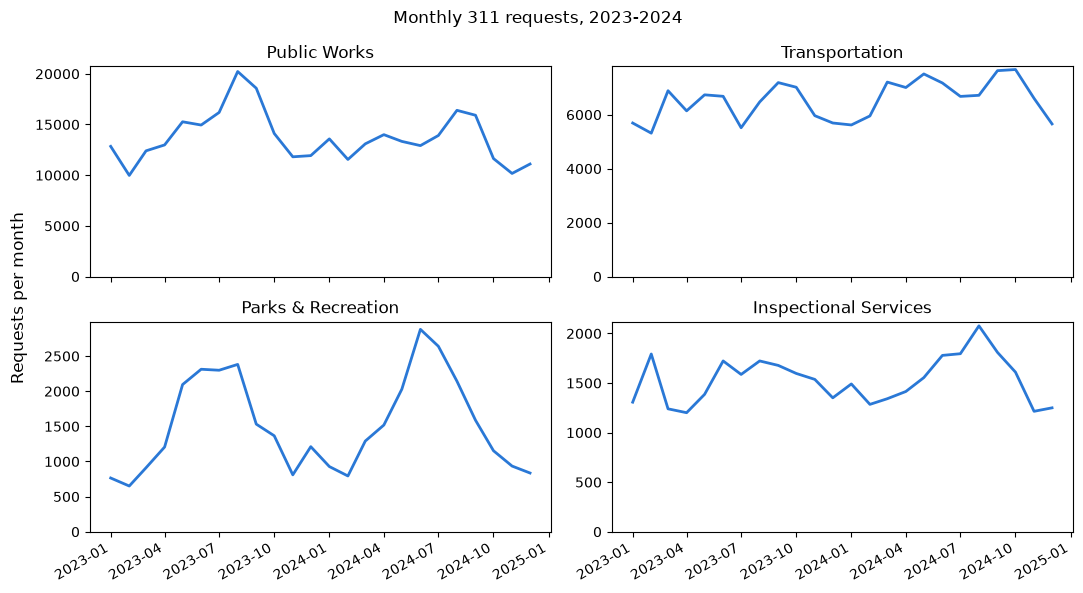

In [6]:
BLUE, GRAY = "#2a78d6", "#888888"

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, (code, d) in zip(axes.flat, DEPTS.items()):
    m = monthly[monthly.dept == code]
    ax.plot(pd.to_datetime(m.month), m.requests, color=BLUE, lw=2)
    ax.set_title(d["name"])
    ax.set_ylim(bottom=0)
fig.supylabel("Requests per month")
fig.suptitle("Monthly 311 requests, 2023-2024")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

Parks is the most seasonal: its June 2024 peak (2,881) is 3.6 times its February low (794), while Transportation stays between about 5,300 and 7,700 a month.

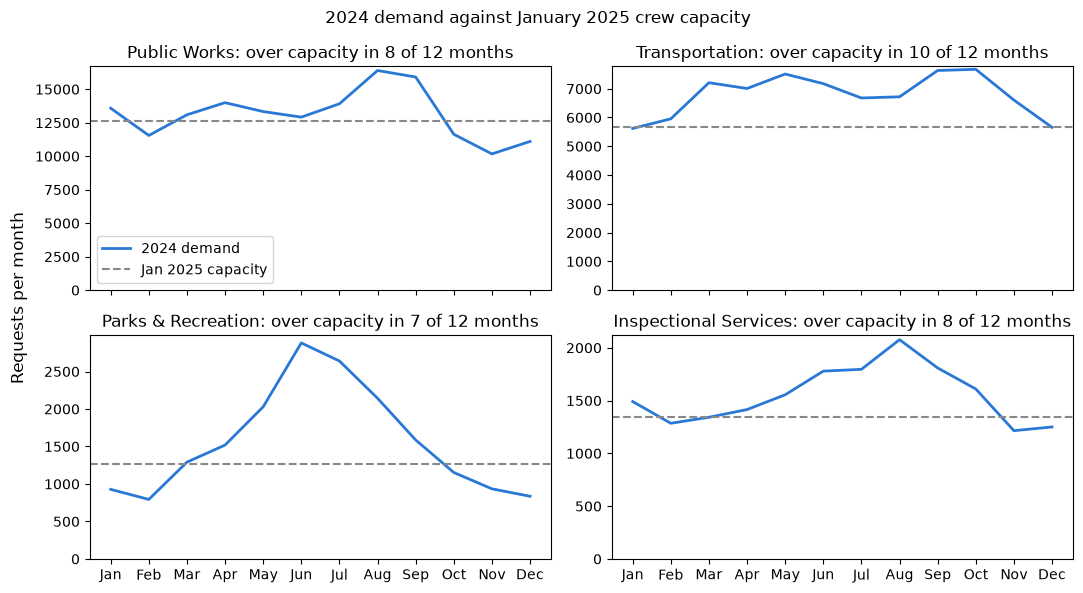

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, (code, d) in zip(axes.flat, DEPTS.items()):
    m = monthly[(monthly.dept == code) & monthly.month.str.startswith("2024")]
    cap = d["jan_crews"] * d["per_crew_day"] * WORK_DAYS
    months = pd.to_datetime(m.month).dt.strftime("%b")
    ax.plot(months, m.requests, color=BLUE, lw=2, label="2024 demand")
    ax.axhline(cap, color=GRAY, ls="--", lw=1.5, label="Jan 2025 capacity")
    ax.set_title(f"{d['name']}: over capacity in {(m.requests > cap).sum()} of 12 months")
    ax.set_ylim(bottom=0)
axes[0, 0].legend()
fig.supylabel("Requests per month")
fig.suptitle("2024 demand against January 2025 crew capacity")
fig.tight_layout()
plt.show()

At January 2025 crew levels, every department would have fallen short in most months of 2024, and Transportation in 10 of 12.

year    2023    2024  growth
dept                        
BTDT   75314   81447   0.081
ISD    18123   18624   0.028
PARK   17541   18736   0.068
PWDx  171268  157610  -0.080


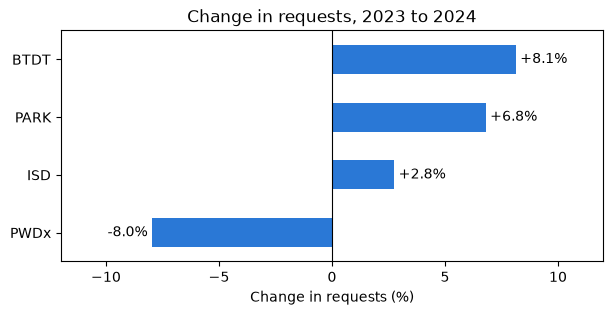

In [8]:
totals = monthly.assign(year=monthly.month.str[:4]).pivot_table(index="dept", columns="year", values="requests", aggfunc="sum")
totals["growth"] = totals["2024"] / totals["2023"] - 1
print(totals.round(3))

ax = totals.growth.sort_values().mul(100).plot.barh(color=BLUE, figsize=(7, 3))
ax.bar_label(ax.containers[0], fmt="%+.1f%%", padding=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-12, 12)
ax.set(xlabel="Change in requests (%)", ylabel="", title="Change in requests, 2023 to 2024")
plt.show()

Transportation, Parks and Inspectional Services grew from 2023 to 2024, but Public Works fell 8.0%, so the forecast's growth term lowers Public Works for 2025.

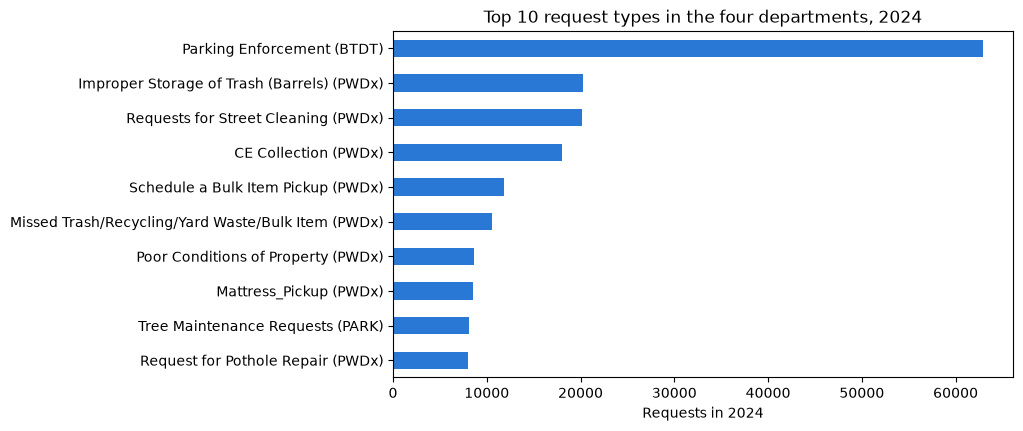

In [9]:
top = df[df.open_dt.dt.year == 2024].groupby(["type", "department"]).size().nlargest(10).sort_values()
ax = top.plot.barh(color=BLUE, figsize=(8, 4.5))
ax.set_yticklabels([f"{t} ({d})" for t, d in top.index])
ax.set(xlabel="Requests in 2024", ylabel="", title="Top 10 request types in the four departments, 2024")
plt.show()

Parking Enforcement alone is 62,973 requests, 77% of Transportation's 2024 volume; Public Works' load is spread across sanitation and street-cleaning types.

## 3. 2025 demand forecast and backtest

Each 2025 month is the average 2023-2024 seasonal shape × the 2024 monthly level × the 2023→2024 growth. The backtest predicts 2024 from 2023 alone (2023 shape × 2023 level, no growth term), because we don't have 2022 data.

In [10]:
m = monthly.assign(year=monthly.month.str[:4], mo=monthly.month.str[5:])
m["seasonal"] = m.requests / m.groupby(["dept", "year"]).requests.transform("mean")
m23, m24 = m[m.year == "2023"], m[m.year == "2024"]

bt = m24.merge(m23[["dept", "mo", "seasonal"]], on=["dept", "mo"], suffixes=("", "_2023"))
bt["pred"] = bt.seasonal_2023 * bt.dept.map(m23.groupby("dept").requests.mean())
mape = (abs(bt.pred - bt.requests) / bt.requests).groupby(bt.dept).mean().mul(100).round(1)
print("Backtest MAPE (%), predicting 2024 from 2023:")
print(mape.to_string())

Backtest MAPE (%), predicting 2024 from 2023:
dept
BTDT     7.6
ISD     13.3
PARK    17.7
PWDx    13.6


In [11]:
fc = m.groupby(["dept", "mo"], as_index=False).seasonal.mean()
fc["forecast"] = (fc.seasonal * fc.dept.map(m24.groupby("dept").requests.mean()) * fc.dept.map(1 + totals.growth)).round().astype(int)
fc["month"] = "2025-" + fc.mo
fc[["dept", "month", "forecast"]].to_csv(PROCESSED / "forecast_2025.csv", index=False)

print(pd.DataFrame({"2024 actual": totals["2024"], "2025 forecast": fc.groupby("dept").forecast.sum()}))
fc.pivot(index="month", columns="dept", values="forecast")

      2024 actual  2025 forecast
dept                            
BTDT        81447          88078
ISD         18624          19140
PARK        18736          20010
PWDx       157610         145040


dept,BTDT,ISD,PARK,PWDx
month,,,,
2025-01,6367,1456,932,11688
2025-02,6328,1607,795,9539
2025-03,7926,1344,1209,11275
2025-04,7381,1361,1499,11939
2025-05,8001,1531,2279,12599
2025-06,7787,1824,2858,12273
2025-07,6837,1761,2721,13257
2025-08,7418,1977,2503,16109
2025-09,8332,1816,1721,15188


The backtest is off by 7.6% a month on average for Transportation and 17.7% for Parks, which was flat from May to August in 2023 but peaked sharply in June 2024. Public Works is forecast at 145,040 requests in 2025, 8.0% below 2024, because the method carries its 2023 to 2024 drop forward; the other three departments grow by 2.8% to 8.1%.

## 4. Staffing plan (MILP) and the hold-flat baseline

Each department gets its own MILP over the 12 months of 2025 (PuLP with HiGHS), on the Section 3 forecast.
- **Variables:** crews, hires, releases and Parks seasonal crews, all whole numbers. A hire is paid in its month while training and works from the next; a release takes effect the next month and costs 25% of annual cost. Seasonal crews work April to October only, at 1.3 × monthly cost.
- **Backlog** is the requests left unserved at month end, carried to the next month.
- **Cost:** crews, hires, release fees and seasonal crews, plus $20 for each newly overdue request and $100 more for one still open a month later (a monthly approximation of "30 days past target").
- **Service rule:** backlog ≤ 10% of the month's demand, from February. **January is exempt**, because its crews are fixed and a hire only works from the next month, so nothing can raise January capacity: Transportation's forecast January is 6,367 against a capacity of 5,670 at 18 crews.
- **Baseline:** hold January crews all year, with no hires, releases or seasonal crews.

`on_time_est = 1 − backlog / demand` is a model estimate, not the city's real on-time rate. `utilization = served / capacity`.

In [12]:
def plan_dept(d, demand, seasonal=False, fixed=None):
    """Min-cost monthly plan for one department. fixed: a plan whose crews, hires, releases and seasonals are kept, with the service rule off."""
    T, monthly, rate = range(len(demand)), d["annual_cost"] / 12, d["per_crew_day"] * WORK_DAYS
    m = pulp.LpProblem("plan", pulp.LpMinimize)
    var = lambda name, cat="Integer": m.add_variable_dicts(name, T, lowBound=0, cat=cat)
    c, h, r, s = var("crews"), var("hires"), var("releases"), var("seasonal")
    served, b, old = var("served", "Continuous"), var("backlog", "Continuous"), var("old", "Continuous")
    crew = {t: (c[t] + h[t]) * monthly + r[t] * RELEASE_FEE * d["annual_cost"] + s[t] * SEASONAL_MULT * monthly for t in T}
    # $20 once per newly overdue request, $100 for one still open a month later
    penalty = {t: OVERDUE_PENALTY * (b[t] - old[t]) + LATE_30_PENALTY * old[t] for t in T}
    m += pulp.lpSum(crew.values()) + pulp.lpSum(penalty.values())
    m += c[0] == d["jan_crews"]
    for t in T:
        prev = b[t - 1] if t else 0
        if t:
            m += c[t] == c[t - 1] + h[t - 1] - r[t - 1]  # hires and releases take effect next month
        m += served[t] <= (c[t] + s[t]) * rate
        m += b[t] == prev + demand[t] - served[t]  # b >= 0 also caps served at what's open
        m += old[t] >= prev - served[t]  # last month's backlog still open after this month
        if not (seasonal and t + 1 in SEASONAL_MONTHS):
            m += s[t] == 0
        if fixed is not None:
            for x, k in ((c, "crews"), (h, "hires"), (r, "releases"), (s, "seasonal")):
                m += x[t] == float(fixed[k][t])  # float(): pulp compares numpy numbers to False
        elif t:  # January is exempt: its crews are fixed, so its capacity can't change
            m += b[t] <= 0.1 * demand[t]
    assert m.solve(pulp.HiGHS(msg=False)).status == pulp.LpSolveStatus.Optimal
    df = pd.DataFrame({k: [round(x[t].value(), 2) + 0 for t in T]  # + 0 turns solver -0.0 into 0.0
                       for k, x in dict(crews=c, hires=h, releases=r, seasonal=s, served=served, backlog=b).items()})
    df.insert(0, "month", range(1, len(demand) + 1))
    df["capacity"] = (df.crews + df.seasonal) * rate
    df["demand"] = demand
    df["utilization"] = df.served / df.capacity
    df["on_time_est"] = (1 - df.backlog / df.demand).clip(lower=0)
    df["crew_cost"] = [pulp.value(crew[t]) for t in T]
    df["penalty"] = [pulp.value(penalty[t]) for t in T]
    df["cost"] = df.crew_cost + df.penalty
    return df


def summarize(p):
    """Year totals for one plan: costs, demand-weighted on-time estimate, utilization, peak crews + seasonals."""
    return dict(crew_cost=p.crew_cost.sum(), penalty=p.penalty.sum(), cost=p.cost.sum(),
                on_time_est=(p.on_time_est * p.demand).sum() / p.demand.sum(),
                utilization=p.served.sum() / p.capacity.sum(), peak_crews=(p.crews + p.seasonal).max())


# Toy check: capacity is 210 per crew, so month 2 needs 2 crews, so hire 1 in month 1
toy = plan_dept({"per_crew_day": 10, "annual_cost": 12_000, "jan_crews": 1}, [210, 420])
assert toy.hires.tolist() == [1, 0] and toy.backlog.tolist() == [0, 0] and toy.cost.tolist() == [2000, 2000]
print("toy check passed: hires", toy.hires.tolist(), "backlog", toy.backlog.tolist(), "cost", toy.cost.tolist())

toy check passed: hires [1.0, 0.0] backlog [0.0, 0.0] cost [2000.0, 2000.0]


In [13]:
forecast = pd.read_csv(PROCESSED / "forecast_2025.csv").sort_values(["dept", "month"])
demand = {k: forecast[forecast.dept == k].forecast.tolist() for k in DEPTS}
runs = {}
for k, d in DEPTS.items():
    runs["plan", k] = plan_dept(d, demand[k], seasonal=(k == "PARK"))
    flat = pd.DataFrame({"crews": d["jan_crews"], "hires": 0, "releases": 0, "seasonal": 0}, index=range(12))
    runs["baseline", k] = plan_dept(d, demand[k], fixed=flat)

summary = pd.DataFrame([dict(dept=k, mode=mode, **summarize(p)) for (mode, k), p in runs.items()]
                       + [dict(dept="All", mode=mode, **summarize(pd.concat(runs[mode, k] for k in DEPTS)))
                          for mode in ("plan", "baseline")])
table = summary.drop(columns="peak_crews").set_index(["dept", "mode"]).loc[[*DEPTS, "All"]]
table.style.format({"crew_cost": "${:,.0f}", "penalty": "${:,.0f}", "cost": "${:,.0f}",
                    "on_time_est": "{:.1%}", "utilization": "{:.1%}"})

In [14]:
def penalty_once(p):
    """Baseline penalty with the $100 charged once per request: serve the oldest requests first, charge $20 on this month's
    unserved requests and $100 on last month's requests still open (older ones have already paid it)."""
    left, pen = [], 0
    for dem, served in zip(p.demand, p.served):
        left.append(dem)
        for i in range(len(left)):
            take = min(served, left[i])
            left[i], served = left[i] - take, served - take
        pen += OVERDUE_PENALTY * left[-1] + (LATE_30_PENALTY * left[-2] if len(left) > 1 else 0)
    return pen


base = summary.set_index(["dept", "mode"]).loc[("All", "baseline")]
once = sum(penalty_once(runs["baseline", k]) for k in DEPTS)
print(f"Baseline as modeled ($100 every month a request stays over a month old): ${base.cost:,.0f}")
print(f"Baseline with the $100 charged once:                               ${base.crew_cost + once:,.0f} (penalty ${once:,.0f})")

Baseline as modeled ($100 every month a request stays over a month old): $22,529,080
Baseline with the $100 charged once:                               $20,081,780 (penalty $8,161,780)


In [15]:
btdt = summary[summary.dept == "BTDT"].set_index("mode")
print("Transportation, plan against hold-flat baseline:")
btdt[["crew_cost", "penalty", "cost", "on_time_est", "utilization", "peak_crews"]].style.format(
    {"crew_cost": "${:,.0f}", "penalty": "${:,.0f}", "cost": "${:,.0f}", "on_time_est": "{:.1%}", "utilization": "{:.1%}", "peak_crews": "{:.0f}"})

Transportation, plan against hold-flat baseline:


,crew_cost,penalty,cost,on_time_est,utilization,peak_crews
mode,,,,,,
plan,"$2,759,167","$35,300","$2,794,467",98.0%,95.4%,26
baseline,"$1,980,000","$6,809,560","$8,789,560",19.7%,100.0%,18


In [16]:
plan = pd.concat({k: runs["plan", k] for k in DEPTS}, names=["dept"]).reset_index(0)
plan["month"] = plan.month.map("2025-{:02d}".format)
cols = ["dept", "month", "crews", "hires", "releases", "seasonal", "capacity", "demand", "backlog", "utilization", "cost"]
plan[cols].round({"backlog": 1, "utilization": 3, "cost": 2}).astype({c: int for c in ["crews", "hires", "releases", "seasonal", "capacity"]}) \
    .to_csv(PROCESSED / "plan_2025.csv", index=False)
plan.pivot(index="month", columns="dept", values=["crews", "hires", "releases", "seasonal"]).astype(int) \
    .swaplevel(axis=1)[list(DEPTS)]

dept     PWDx                          BTDT                          PARK  \
        crews hires releases seasonal crews hires releases seasonal crews   
month                                                                       
2025-01    50     0        0        0    18     4        0        0    10   
2025-02    50     0        0        0    22     2        0        0    10   
2025-03    50     0        0        0    24     1        0        0    10   
2025-04    50     0        0        0    25     0        0        0    10   
2025-05    50     0        0        0    25     0        0        0    10   
2025-06    50     2        0        0    25     0        0        0    10   
2025-07    52     8        0        0    25     0        0        0    10   
2025-08    60     0        1        0    25     1        0        0    10   
2025-09    59     0        0        0    26     0        0        0    10   
2025-10    59     0        0        0    26     0        0        0    10   
2025-11    59     0        0        0    26     0        0        0    10   
2025-12    59     0        0        0    26     0        0        0    10   

dept                              ISD                          
        hires releases seasonal crews hires releases seasonal  
month                                                          
2025-01     0        0        0    16     3        0        0  
2025-02     0        0        0    19     0        0        0  
2025-03     0        0        0    19     0        0        0  
2025-04     0        0        2    19     0        0        0  
2025-05     0        0        8    19     2        0        0  
2025-06     0        0       12    21     0        0        0  
2025-07     0        0       12    21     1        0        0  
2025-08     0        0       10    22     0        0        0  
2025-09     0        0        4    22     0        0        0  
2025-10     0        0        0    22     0        0        0  
2025-11     0        0        0    22     0        0        0  
2025-12     0        0        0    22     0        0        0

The plan costs $14.77M against $22.53M for the hold-flat baseline: $2.74M more on crews avoids $10.5M of backlog penalties and lifts the on-time estimate from 56.7% to 98.0%. Transportation gains the most: 8 hires take it from 18 to 26 crews, its cost falls from $8.79M to $2.79M, and its on-time estimate rises from 19.7% to 98.0%. Public Works hires 10 for the August peak and releases 1 after it, and Parks needs no permanent hires, only seasonal crews (up to 12 in June and July). The baseline's penalty is an upper bound, because with no hires its backlog keeps growing all year and the $100 is charged every month; charged once, the baseline is $20.08M, so the plan saves $5.31M to $7.76M.

## 5. Sensitivity: demand ±20%, snowstorm, heat wave

Four scenarios change the Section 3 forecast: demand × 0.8 and × 1.2 in every department and month; a snowstorm (Public Works +35% in January and February); and a heat wave (Parks +40% and Public Works +10% in July). Each runs two ways:
- **replanned:** the Section 4 model solved again on the scenario's demand.
- **base_kept:** Section 4's crews, hires, releases and seasonal crews kept, the service rule off, and the same cost formula, so unmet demand shows up as backlog penalties.

`on_time_est` is demand-weighted over the year, and `peak_crews` is the largest monthly count of crews plus seasonal crews, so Parks' summer seasonal crews count.

In [17]:
SCENARIOS = {
    "demand x0.8": lambda k, mo: 0.8,
    "demand x1.2": lambda k, mo: 1.2,
    "snowstorm": lambda k, mo: 1.35 if k == "PWDx" and mo in (1, 2) else 1,
    "heat wave": lambda k, mo: {"PARK": 1.4, "PWDx": 1.1}.get(k, 1) if mo == 7 else 1,
}
rows = []
for name, factor in SCENARIOS.items():
    for k, d in DEPTS.items():
        dem = [x * factor(k, mo) for mo, x in enumerate(demand[k], 1)]
        for mode, fixed in (("replanned", None), ("base_kept", runs["plan", k])):
            rows.append(dict(scenario=name, mode=mode, dept=k, **summarize(plan_dept(d, dem, seasonal=(k == "PARK"), fixed=fixed))))
scen = pd.DataFrame(rows)
scen[["scenario", "mode", "dept", "cost", "on_time_est", "peak_crews"]].round({"cost": 2, "on_time_est": 3}) \
    .astype({"peak_crews": int}).to_csv(PROCESSED / "scenarios.csv", index=False)
scen.pivot(index=["scenario", "dept"], columns="mode", values=["cost", "on_time_est", "peak_crews"]) \
    .loc[list(SCENARIOS)].style.format("${:,.0f}", subset="cost").format("{:.1%}", subset="on_time_est").format("{:.0f}", subset="peak_crews")

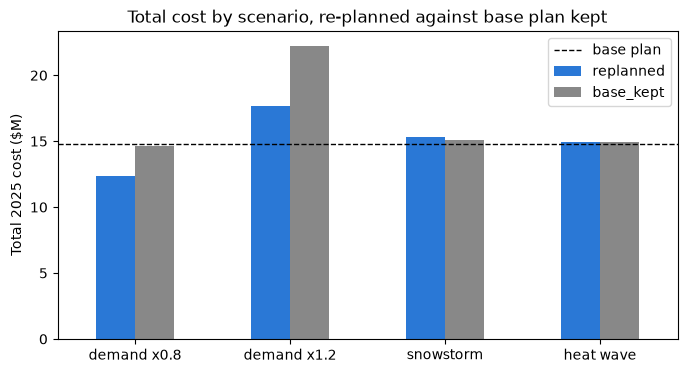

mode         replanned  base_kept
scenario                         
demand x0.8      12.37      14.66
demand x1.2      17.67      22.25
snowstorm        15.35      15.10
heat wave        14.94      14.97


In [18]:
base_cost = summary.set_index(["dept", "mode"]).loc[("All", "plan"), "cost"]
cost = scen.pivot_table(index="scenario", columns="mode", values="cost", aggfunc="sum").loc[list(SCENARIOS), ["replanned", "base_kept"]] / 1e6
ax = cost.plot.bar(color=[BLUE, GRAY], figsize=(8, 4), rot=0)
ax.axhline(base_cost / 1e6, color="black", ls="--", lw=1, label="base plan")
ax.set(xlabel="", ylabel="Total 2025 cost ($M)", title="Total cost by scenario, re-planned against base plan kept")
ax.legend()
plt.show()
print(cost.round(2).to_string())

Re-planning saves the most when demand moves all year: $2.3M at ×0.8, by not hiring, and $4.6M at ×1.2, by hiring instead of paying penalties. For the one-month snowstorm and heat wave, keeping the base plan costs about the same or less ($15.10M against $15.35M for the snowstorm), because re-planning pays for hires to meet the 10% rule that the kept plan ignores.

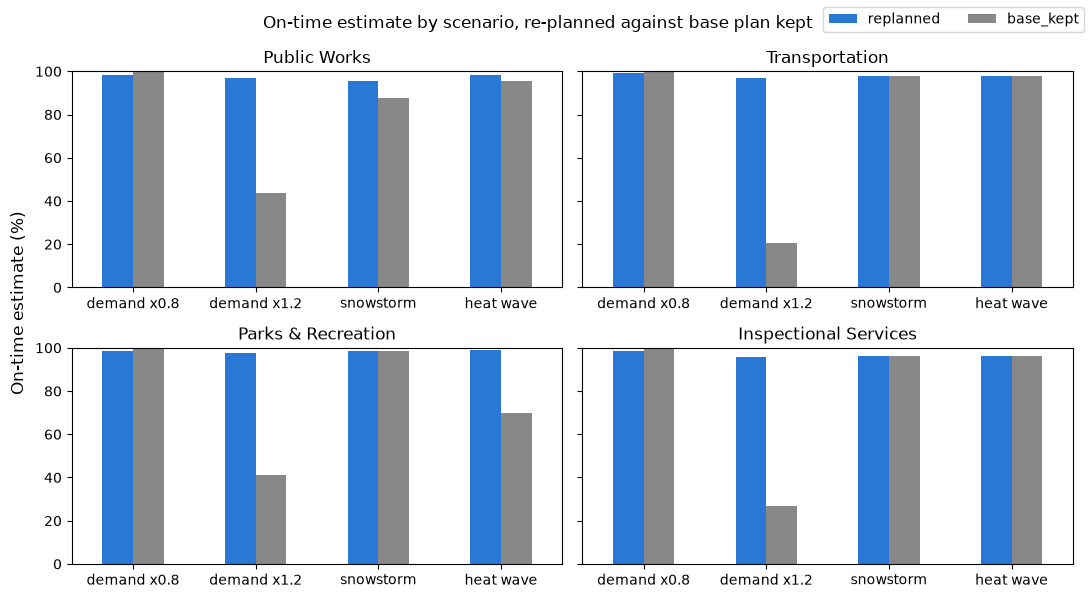

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharey=True)
for ax, (code, d) in zip(axes.flat, DEPTS.items()):
    s = scen[scen.dept == code].pivot(index="scenario", columns="mode", values="on_time_est").loc[list(SCENARIOS), ["replanned", "base_kept"]]
    s.mul(100).plot.bar(ax=ax, color=[BLUE, GRAY], rot=0, legend=False)
    ax.set(title=d["name"], xlabel="")
    ax.set_ylim(0, 100)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper right", ncol=2)
fig.supylabel("On-time estimate (%)")
fig.suptitle("On-time estimate by scenario, re-planned against base plan kept")
fig.tight_layout()
plt.show()

With the base plan kept, a 20% rise drops the on-time estimate to 21–44% in every department, while re-planning holds it at 96–97%; the heat wave hits Parks hardest (69.9% kept against 99.1% re-planned), and the snowstorm takes Public Works to 87.5%.

## 6. 311 intake assistant and its accuracy

We route a resident's message to one of the 170 request types the city used in 2024, and look up its department and queue. The assistant suggests a routing; it doesn't replace 311 staff.

1. **Retrieve** the 5 request types closest to the message. Each type is embedded as its name and its category (`reason`), locally with `BAAI/bge-small-en-v1.5`.
2. **One structured-output call** to Groq's gpt-oss. The schema only allows those 5 types or `OUT_OF_SCOPE`, in strict mode, so the model can't invent a type. It also says whether the message needs clarifying, and asks one follow-up question if so.
3. **Department and queue** come from `request_types.csv` (each type's most common 2024 routing), never from the model.

| Technique | Where |
|---|---|
| API calls (Groq) | `ChatGroq`, temperature 0, every call cached in `data/cache/` |
| Prompt engineering | The system prompt's routing rules: main problem first, when to use `OUT_OF_SCOPE`, when to ask a follow-up |
| Structured output | `with_structured_output(..., method="json_schema", strict=True)` with the allowed types as an enum |
| LangChain | Chat model, embeddings, vector store and structured output |
| RAG | The 5 retrieved types and their categories go into the prompt as the only choices |

In [20]:
from typing import Literal

import groq
from langchain_community.embeddings import FastEmbedEmbeddings
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_groq import ChatGroq
from pydantic import Field, create_model

# One document per 2024 request type: its name and its reason (each type has exactly one)
docs = con.sql("select type, any_value(reason) as reason from raw where year(open_dt) = 2024 group by type order by type").df()
store = InMemoryVectorStore(FastEmbedEmbeddings(model_name="BAAI/bge-small-en-v1.5"))
store.add_documents([Document(f"{t} | {r}", metadata={"type": t}) for t, r in zip(docs.type, docs.reason)])

# Department and queue for each type: its most common 2024 routing
route_of = types.drop_duplicates("type").set_index("type")  # types is sorted by n_2024 within each type
same_dept = types.dept == types.type.map(route_of.dept)
print(f"Routing each type to its most common pair matches the 2024 department for {types.n_2024[same_dept].sum() / types.n_2024.sum():.1%} of requests")

llm = ChatGroq(model=LLM_MODEL, temperature=0, max_retries=10)  # free tier: 8,000 tokens a minute, so calls wait and retry

SYSTEM = """You route messages from Boston residents to a City of Boston 311 request type.
Pick the one candidate type that best matches the resident's main problem. If the message names several problems, pick the first or most urgent one.
Pick OUT_OF_SCOPE only if the message is not a request for a city service at all (for example a general question or a private matter).
If the message is too vague to be sure, still pick the most likely type, set needs_clarification to true, and write one short follow_up_question that would settle it. Otherwise leave follow_up_question empty."""


def intake(message):
    hits = store.similarity_search(message, k=5)
    options = [h.metadata["type"] for h in hits]
    Route = create_model("Route", request_type=(Literal[tuple(options + ["OUT_OF_SCOPE"])], ...), needs_clarification=(bool, ...),
                         follow_up_question=(str, Field(description="One short question, or empty")))
    candidates = "\n".join(f"- {h.page_content}" for h in hits)
    # Groq sometimes fails a strict-schema generation with a 400; a retry succeeds
    out = llm.with_structured_output(Route, method="json_schema", strict=True).with_retry(
        retry_if_exception_type=(groq.BadRequestError,), stop_after_attempt=3).invoke(
        [("system", SYSTEM), ("human", f"Candidate types (name | category):\n{candidates}\n\nMessage: {message}")])
    row = route_of.loc[out.request_type] if out.request_type in route_of.index else None
    return dict(type=out.request_type, dept=None if row is None else row.dept, queue=None if row is None else row.queue,
                needs_clarification=out.needs_clarification, follow_up_question=out.follow_up_question, candidates=options)


pd.DataFrame([dict(message=m, **intake(m)) for m in
              ["my recycling bin got crushed by the truck", "something smells weird", "is the library open on sunday?"]]).drop(columns="candidates")

Routing each type to its most common pair matches the 2024 department for 94.9% of requests


,message,type,dept,queue,needs_clarification,follow_up_question
0,my recycling bin got crushed by the truck,Missed Trash/Recycling/Yard Waste/Bulk Item,PWDx,PWDx_Missed Trash\Recycling\Yard Waste\Bulk Item,False,
1,something smells weird,Chronic Dampness/Mold,ISD,ISD_Housing (INTERNAL),True,Can you describe the smell and where you are n...
2,is the library open on sunday?,OUT_OF_SCOPE,NaN,NaN,False,


**Accuracy on the test set.** These are Ram's 30 test messages, labeled from `request_types.csv`; the prompt was not tuned on them. A department counts as correct when it matches, or when both the label and the prediction are out of scope. `in_top5` shows whether retrieval offered the right type at all.

In [21]:
test = pd.read_csv(ROOT / "data/intake_test_set.csv")
res = pd.DataFrame([intake(m) for m in test.message])
test["pred_type"], test["pred_dept"], test["clarify"] = res.type, res.dept, res.needs_clarification
test["in_top5"] = [t in c or t == "OUT_OF_SCOPE" for t, c in zip(test.type, res.candidates)]
test["type_ok"] = test.type == test.pred_type
test["dept_ok"] = test.dept.fillna("") == test.pred_dept.fillna("")

print(f"Type accuracy:       {test.type_ok.sum()}/{len(test)} ({test.type_ok.mean():.0%})")
print(f"Department accuracy: {test.dept_ok.sum()}/{len(test)} ({test.dept_ok.mean():.0%})")
print(f"Right type in the retrieved 5: {test.in_top5.sum()}/{len(test)}")
display(test.groupby("kind").agg(messages=("type", "size"), type_ok=("type_ok", "sum"), dept_ok=("dept_ok", "sum"),
                                 asked_follow_up=("clarify", "sum")))
test.loc[~test.type_ok | ~test.dept_ok, ["message", "kind", "type", "pred_type", "dept", "pred_dept", "in_top5"]]

Type accuracy:       23/30 (77%)
Department accuracy: 30/30 (100%)
Right type in the retrieved 5: 24/30


,messages,type_ok,dept_ok,asked_follow_up
kind,,,,
ambiguous,5,2,5,2
clear,18,15,18,0
multi,4,3,4,0
out_of_scope,3,3,3,0


,message,kind,type,pred_type,dept,pred_dept,in_top5
4,Someone dumped a pile of tires and constructio...,clear,Illegal Dumping,Construction Debris,PWDx,PWDx,False
6,the stop sign at Walnut and Elm got knocked ov...,clear,Sign Repair,Missing Sign,BTDT,BTDT,False
15,something is wrong with the road on my street,ambiguous,Request for Pothole Repair,Sidewalk Repair,PWDx,PWDx,False
17,there's so much trash around here,ambiguous,Requests for Street Cleaning,Trash on Vacant Lot,PWDx,PWDx,False
18,the park near me is in really bad shape,ambiguous,Ground Maintenance,Park Improvement Requests,PARK,PARK,False
21,Someone has been parked across my driveway all...,multi,Parking Enforcement,Private Parking Lot Complaints,BTDT,BTDT,True
26,The storm drain at the corner of my street is ...,clear,Catchbasin,Roadway Flooding,BWSC,BWSC,False


With `gpt-oss-120b`, the assistant picks the right request type for 23 of 30 test messages (77%) and the right department for all 30. Six of the seven type misses are retrieval misses: the right type wasn't among the 5 retrieved, and each time the model still chose a type in the right department. The seventh is a two-issue message (a car blocking a driveway and a missing sign), routed to Private Parking Lot Complaints instead of Parking Enforcement. It sent all 3 non-311 messages to `OUT_OF_SCOPE` and asked a follow-up on 2 of the 5 ambiguous messages (that count varies between runs), so retrieval is the main thing to improve.

## 7. Planner agent with 5 tools

A LangChain agent (`create_agent`) answers planning questions with five tools. Each tool reads only the CSVs the sections above wrote, and the system prompt tells the agent to state only numbers a tool returned.

| Tool | Reads | Returns |
|---|---|---|
| `route_request` | the Section 6 intake assistant | type, department, queue, follow-up question |
| `get_plan` | `plan_2025.csv` | 2025 totals per department, or one month's crews, hires, backlog and cost |
| `what_if` | `scenarios.csv`, `plan_2025.csv` | a scenario's cost, on-time estimate and peak crews, re-planned and with the base plan kept, next to the base plan |
| `get_forecast` | `forecast_2025.csv`, `monthly_demand.csv` | the 2025 forecast next to the same month in 2024 |
| `neighborhood_stats` | `neighborhood_stats.csv` | 2024 on-time rate by neighborhood, or a neighborhood's top request types |

In [22]:
from langchain.agents import create_agent
from langchain_core.tools import tool

plan_csv, scen_csv = pd.read_csv(PROCESSED / "plan_2025.csv"), pd.read_csv(PROCESSED / "scenarios.csv")
fcst_csv, hist_csv = pd.read_csv(PROCESSED / "forecast_2025.csv"), pd.read_csv(PROCESSED / "monthly_demand.csv")
nbhd_csv = pd.read_csv(PROCESSED / "neighborhood_stats.csv")
Dept = Literal["PWDx", "BTDT", "PARK", "ISD"]


def year_totals(p):
    g = p.groupby("dept")
    return pd.DataFrame({"cost": g.cost.sum().round().astype(int), "hires": g.hires.sum(), "releases": g.releases.sum(),
                         "peak_crews": (p.crews + p.seasonal).groupby(p.dept).max(),
                         "on_time_est": (1 - g.backlog.sum() / g.demand.sum()).round(3)})


@tool
def route_request(message: str) -> str:
    """Route a resident's description of a problem to a Boston 311 request type, department and queue."""
    r = intake(message)
    return str({k: r[k] for k in ("type", "dept", "queue", "needs_clarification", "follow_up_question")})


@tool
def get_plan(dept: Dept | None = None, month: str | None = None) -> str:
    """The optimized 2025 crew plan. Without month: 2025 totals per department (cost in $, hires, releases, peak crews, on-time estimate).
    With month (YYYY-MM, e.g. 2025-08): that month's crews, hires, releases, seasonal crews, capacity, demand, backlog, utilization and cost."""
    p = plan_csv if dept is None else plan_csv[plan_csv.dept == dept]
    if month is None:
        return year_totals(p).to_csv()
    p = p[p.month == month].assign(on_time_est=lambda x: (1 - x.backlog / x.demand).round(3), cost=lambda x: x.cost.round().astype(int))
    return p.to_csv(index=False) if len(p) else f"No plan rows for {month}; months run 2025-01 to 2025-12."


@tool
def what_if(scenario: Literal["demand x0.8", "demand x1.2", "snowstorm", "heat wave"], dept: Dept | None = None) -> str:
    """Cost ($), on-time estimate and peak crews under a scenario, two ways: replanned (crews re-optimized) and base_kept (the base plan kept),
    their difference (replanned minus base_kept), and the base plan's own numbers. Snowstorm: Public Works +35% in Jan-Feb. Heat wave: Parks +40% and Public Works +10% in July."""
    base = year_totals(plan_csv)[["cost", "on_time_est", "peak_crews"]].reset_index().assign(scenario="none", mode="base plan")
    s = scen_csv[scen_csv.scenario == scenario].set_index(["dept", "mode"])
    # Give the comparison too, so the agent never has to subtract
    num = s[["cost", "on_time_est"]]
    diff = (num.xs("replanned", level="mode") - num.xs("base_kept", level="mode")).reset_index()
    diff = diff.assign(scenario=scenario, mode="replanned minus base_kept", on_time_est=diff.on_time_est.round(3))
    out = pd.concat([s.reset_index(), diff, base]).astype({"cost": float}).round({"cost": 0}).astype({"cost": int, "peak_crews": "Int64"})
    out = out if dept is None else out[out.dept == dept]
    return out[["scenario", "mode", "dept", "cost", "on_time_est", "peak_crews"]].to_csv(index=False)


@tool
def get_forecast(dept: Dept | None = None, month: str | None = None) -> str:
    """Forecast 2025 requests per month next to the same month's actual 2024 requests, and the 2025 total. month as YYYY-MM, or omit for all months."""
    actual = hist_csv.set_index(hist_csv.dept + hist_csv.month).requests
    f = fcst_csv.assign(actual_2024=(fcst_csv.dept + fcst_csv.month.str.replace("2025", "2024")).map(actual))
    f = f if dept is None else f[f.dept == dept]
    f = f if month is None else f[f.month == month]
    return f.to_csv(index=False) + "\n2025 total forecast by dept:\n" + f.groupby("dept").forecast.sum().to_csv()


@tool
def neighborhood_stats(dept: Dept, neighborhood: str | None = None) -> str:
    """2024 on-time rate by neighborhood for one department. Without neighborhood: requests and on-time rate per neighborhood with at least 100 requests.
    With neighborhood: its top 10 request types with requests, on-time rate and median days to close."""
    n = nbhd_csv[nbhd_csv.dept == dept]
    if neighborhood is None:
        g = n.assign(ontime=n.requests * n.on_time_rate).groupby("neighborhood")[["requests", "ontime"]].sum()
        g = g[g.requests >= 100]  # as in Section 9: smaller groups give unreliable rates
        return (g.assign(on_time_rate=(g.ontime / g.requests).round(3)).drop(columns="ontime").sort_values("on_time_rate").to_csv()
                + "Neighborhoods with fewer than 100 requests are left out.")
    n = n[n.neighborhood.str.lower() == neighborhood.lower()]
    if n.empty:
        return f"No data for {neighborhood}. Neighborhoods: {', '.join(sorted(nbhd_csv.neighborhood.unique()))}"
    return n.nlargest(10, "requests").astype({"median_days": object}).fillna({"median_days": "no closed requests"}).to_csv(index=False)


agent = create_agent(llm, [route_request, get_plan, what_if, get_forecast, neighborhood_stats], system_prompt="""You answer questions about the City of Boston's 2025 field crew plan for four departments:
PWDx (Public Works), BTDT (Transportation), PARK (Parks & Recreation) and ISD (Inspectional Services).
Use the tools for every number. Quote numbers exactly as a tool returns them, and never calculate new ones (no differences, sums or percentages);
if the tools don't have a number, say so. When you compare, give the number for each side the question asks about, and name its plan or mode
(base plan, replanned, base_kept).
on_time_est is a model estimate (1 - backlog / demand), not the city's real on-time rate. Costs are in dollars. Keep answers short.""")


def ask(question, history=()):
    msgs = agent.invoke({"messages": [*history, ("human", question)]})["messages"]
    return msgs[-1].content, [f"{c['name']}({c['args']})" for m in msgs for c in getattr(m, "tool_calls", [])]


for q in ["How many crews does Transportation have in August 2025, and how much does its plan cost for the year?",
          "If demand is 20% higher, how do Parks' cost and on-time estimate compare between re-planning and keeping the base plan?",
          "Which neighborhood has the lowest on-time rate for Transportation, and what is that rate?"]:
    answer, calls = ask(q)
    print(f"Q: {q}\nTools called: {calls}\nA: {answer}\n")

Q: How many crews does Transportation have in August 2025, and how much does its plan cost for the year?
Tools called: ["get_plan({'dept': 'BTDT', 'month': '2025-08'})", "get_plan({'dept': 'BTDT'})"]
A: Transportation (BTDT) has **25 crews** in August 2025, and its 2025 plan costs **$2,794,467** for the year.

Q: If demand is 20% higher, how do Parks' cost and on-time estimate compare between re-planning and keeping the base plan?
Tools called: ["what_if({'dept': 'PARK', 'scenario': 'demand x1.2'})"]
A: - **Re‑planned (replanned)** – Cost $2,167,336; on‑time estimate 0.974  
- **Base plan kept (base_kept)** – Cost $2,746,512; on‑time estimate 0.411

Q: Which neighborhood has the lowest on-time rate for Transportation, and what is that rate?
Tools called: ["neighborhood_stats({'dept': 'BTDT'})"]
A: The neighborhood with the lowest on‑time rate for Transportation (BTDT) is **West Roxbury**, with an on‑time rate of **0.365**.



Each answer uses one or two tool calls, and every number in it appears in that tool's output: 25 crews and $2,794,467 for Transportation, $2,167,336 re-planned against $2,746,512 with the base plan kept for Parks at ×1.2, and West Roxbury's 0.365 on-time rate.

## 8. Gradio app

One app with six tabs, built from the tables above: the 2025 plan, the forecast, the scenarios, the intake assistant from Section 6 (with the routing and the 5 retrieved candidates beside the chat), the planner agent from Section 7 (with the tools it called), and on-time rates by neighborhood.

In [23]:
import gradio as gr
from matplotlib.figure import Figure  # not pyplot, so building the app doesn't draw a figure in the notebook

DEPT_NAMES = {d["name"]: k for k, d in DEPTS.items()}
by_dept = summary.set_index(["dept", "mode"])
btdt_plan = plan[plan.dept == "BTDT"]
SUMMARY = (f"The plan costs **${by_dept.loc[('All', 'plan'), 'cost'] / 1e6:.2f}M** for 2025, against "
           f"**${by_dept.loc[('All', 'baseline'), 'cost'] / 1e6:.2f}M** for holding January's crews all year. "
           f"Transportation goes from **{int(btdt_plan.crews.iloc[0])} crews** in January to a peak of **{int((btdt_plan.crews + btdt_plan.seasonal).max())}**.")


def plan_view(name):
    p = plan[plan.dept == DEPT_NAMES[name]].assign(date=lambda x: pd.to_datetime(x.month))
    lines = pd.concat([p.assign(crews=p.crews + p.seasonal, series="Plan (incl. seasonal)"),
                       p.assign(crews=DEPTS[DEPT_NAMES[name]]["jan_crews"], series="January crews")])[["date", "crews", "series"]]
    table = p[["month", "crews", "hires", "releases", "seasonal", "demand", "capacity", "utilization", "on_time_est"]].round(
        {"utilization": 3, "on_time_est": 3}).astype({c: int for c in ["crews", "hires", "releases", "seasonal", "demand", "capacity"]})
    return lines, table


def forecast_view(name):
    k = DEPT_NAMES[name]
    lines = pd.concat([monthly[monthly.dept == k].assign(series="2023–2024 actual"),
                       fc[fc.dept == k].rename(columns={"forecast": "requests"}).assign(series="2025 forecast")])
    lines = lines.assign(date=pd.to_datetime(lines.month))[["date", "requests", "series"]]
    return lines, f"Backtest (2024 predicted from 2023): mean absolute percentage error **{mape[k]:.1f}%** a month."


MODES = {"replanned": "re-planned", "base_kept": "base plan kept"}


def scenario_view(name):
    s = scen[scen.scenario == name].assign(department=lambda x: x.dept.map({k: d["name"] for k, d in DEPTS.items()}),
                                           mode=lambda x: x["mode"].map(MODES))
    # BarPlot stacks bars that share an x value, so each department and mode gets its own bar, side by side
    bars = s.assign(bar=s.dept + ", " + s["mode"])[["bar", "mode", "cost"]]
    table = s.pivot(index="department", columns="mode", values=["cost", "on_time_est", "peak_crews"]).loc[list(DEPT_NAMES)]
    table.columns = [f"{v} ({m})" for v, m in table.columns]
    ints = [c for c in table.columns if c.startswith(("cost", "peak"))]
    table = table.round(3).round({c: 0 for c in ints}).reset_index().astype({c: int for c in ints})
    return bars, table


def report_reply(message, history):
    # Route on everything the resident has said so far, so answering the follow-up refines the routing
    said = " ".join([m["content"] for m in history if m["role"] == "user" and isinstance(m["content"], str)] + [message])
    r = intake(said)
    if r["type"] == "OUT_OF_SCOPE":
        return ("That doesn't look like a 311 service request. For a city service, describe the problem and where it is.",
                "### Not a 311 request\nThe assistant picked `OUT_OF_SCOPE`.")
    card = f"### Suggested routing\n**Request type:** {r['type']}  \n**Department:** {r['dept']}  \n**Queue:** {r['queue']}\n\n"
    if r["needs_clarification"] and r["follow_up_question"]:
        return f"Suggested routing: **{r['type']}**.\n\n{r['follow_up_question']}", card + f"**Follow-up question:** {r['follow_up_question']}"
    return (f"Suggested routing: **{r['type']}**, department {r['dept']}, queue {r['queue']}.",
            card + "**The 5 retrieved candidates:**\n" + "\n".join(f"{i}. {t}" for i, t in enumerate(r["candidates"], 1)))


def planner_reply(message, history):
    answer, calls = ask(message, [(m["role"], m["content"]) for m in history if isinstance(m["content"], str)])
    return answer, "### Tools used\n" + ("\n".join(f"- `{c}`" for c in calls) or "No tool calls for this answer.")


def neighborhood_view(name):
    n = nbhd_csv[nbhd_csv.dept == DEPT_NAMES[name]]
    g = n.assign(ontime=n.requests * n.on_time_rate).groupby("neighborhood")[["requests", "ontime"]].sum()
    g = g[g.requests >= 50].assign(rate=lambda x: x.ontime / x.requests).sort_values("rate", ascending=False)
    fig = Figure(figsize=(8, 6), layout="constrained")
    ax = fig.subplots()
    ax.barh(g.index, g.rate * 100, color="#10b981")
    ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3, fontsize=8)
    ax.set(xlim=(0, 105), xlabel="On time, 2024 (%)", title=f"{name}, 2024 (neighborhoods with 50+ requests)")
    return fig


with gr.Blocks(title="Boston 311 Crew Planner") as app:
    gr.Markdown("# Boston 311 Crew Planner\n2025 field crews for four City of Boston departments, planned from real 311 data.")
    with gr.Tabs():
        with gr.Tab("2025 plan"):
            gr.Markdown(SUMMARY)
            dept1 = gr.Dropdown(list(DEPT_NAMES), value="Transportation", label="Department")
            lines, table = plan_view("Transportation")
            crews_plot = gr.LinePlot(lines, x="date", y="crews", color="series", title="Crews per month", y_title="Crews", y_lim=[0, None])
            plan_table = gr.Dataframe(table, label="Month by month")
            dept1.change(plan_view, dept1, [crews_plot, plan_table])
        with gr.Tab("Forecast"):
            dept2 = gr.Dropdown(list(DEPT_NAMES), value="Transportation", label="Department")
            lines, note = forecast_view("Transportation")
            fc_plot = gr.LinePlot(lines, x="date", y="requests", color="series", title="Requests per month", y_title="Requests", y_lim=[0, None])
            mape_md = gr.Markdown(note)
            dept2.change(forecast_view, dept2, [fc_plot, mape_md])
        with gr.Tab("Scenarios"):
            sc = gr.Dropdown(list(SCENARIOS), value="snowstorm", label="Scenario")
            bars, table = scenario_view("snowstorm")
            sc_plot = gr.BarPlot(bars, x="bar", y="cost", color="mode", title="2025 cost by department ($)", x_title=" ", y_title="Cost ($)",
                                 sort=[f"{k}, {m}" for k in DEPTS for m in MODES.values()])
            sc_table = gr.Dataframe(table, label="Re-planned against base plan kept")
            gr.Markdown("After a one-month shock, re-planning buys on-time service rather than savings.")
            sc.change(scenario_view, sc, [sc_plot, sc_table])
        with gr.Tab("Report a problem"):
            card = gr.Markdown("### Suggested routing\nSend a message to see the routing here.", render=False)
            with gr.Row():
                with gr.Column(scale=3):
                    gr.ChatInterface(report_reply, additional_outputs=[card],
                                     examples=["There's a big hole on Centre St near the T stop", "The light is out"])
                with gr.Column(scale=2):
                    card.render()
        with gr.Tab("Ask the planner"):
            tools_md = gr.Markdown("### Tools used\nAsk a question to see which tools the agent called.", render=False)
            with gr.Row():
                with gr.Column(scale=3):
                    gr.ChatInterface(planner_reply, additional_outputs=[tools_md], examples=[
                        "If demand is 20% higher, how do Transportation's cost and on-time estimate compare between re-planning and keeping the base plan?"])
                with gr.Column(scale=2):
                    tools_md.render()
        with gr.Tab("Neighborhoods"):
            dept6 = gr.Dropdown(list(DEPT_NAMES), value="Transportation", label="Department")
            nb_plot = gr.Plot(neighborhood_view("Transportation"), show_label=False)
            dept6.change(neighborhood_view, dept6, nb_plot)

app.launch(share=False, prevent_thread_lock=True, theme=gr.themes.Soft(primary_hue="emerald", neutral_hue="slate"))

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


The app runs on localhost, so the frame above is blank in the saved notebook. Screenshots of the running app:

![The 2025 plan tab](../assets/app_plan.png)

![The Report a problem tab](../assets/app_intake.png)

## 9. Other considerations: neighborhood equity, resident versus employee requests

2024 requests only. The on-time rate uses the city's `on_time` flag over all requests, so a request with no target date counts as on time; median days to close is over closed requests. Duplicate neighborhood spellings are merged, the 1,899 requests with no neighborhood are dropped, and "Boston" means no specific neighborhood was given.

In [24]:
import numpy as np

merge = {"South Boston": "South Boston / South Boston Waterfront", "Allston": "Allston / Brighton",
         "Brighton": "Allston / Brighton", "Mattapan": "Greater Mattapan"}
d24 = df[(df.open_dt.dt.year == 2024) & df.neighborhood.notna()].copy()
d24["neighborhood"] = d24.neighborhood.replace(merge)
d24["ontime"] = d24.on_time == "ONTIME"
d24["days"] = (d24.closed_dt - d24.open_dt).dt.total_seconds() / 86400

stats = (d24.groupby(["department", "type", "neighborhood"])
         .agg(requests=("ontime", "size"), on_time_rate=("ontime", "mean"), median_days=("days", "median"))
         .round({"on_time_rate": 3, "median_days": 2}).reset_index().rename(columns={"department": "dept"}))
stats.to_csv(PROCESSED / "neighborhood_stats.csv", index=False)
print(f"{len(stats):,} dept/type/neighborhood rows, {stats.neighborhood.nunique()} neighborhoods")

2,947 dept/type/neighborhood rows, 19 neighborhoods


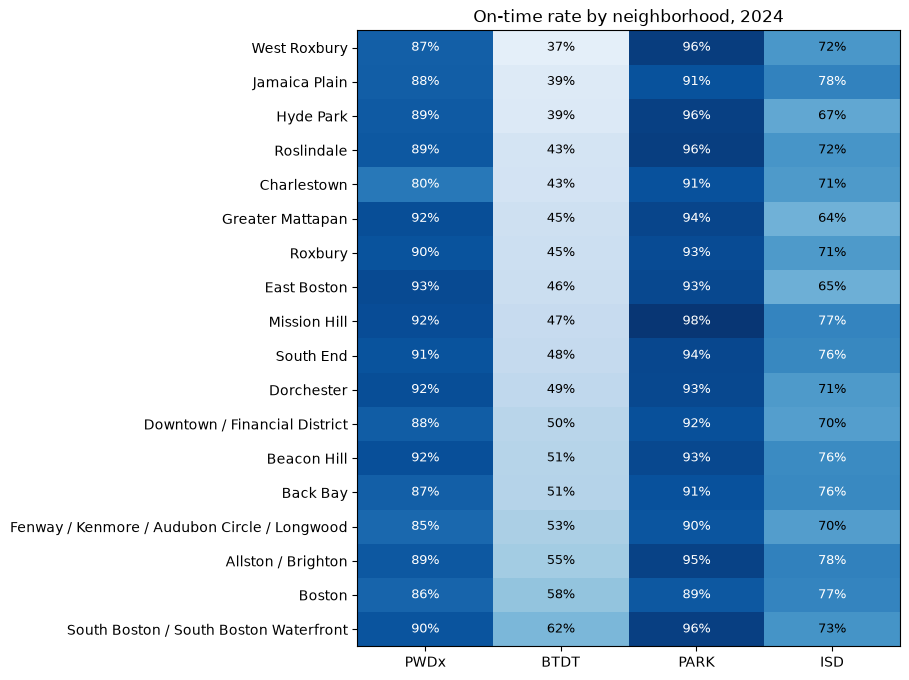

department
PWDx    12.2
BTDT    25.5
PARK     9.0
ISD     14.1
Left out of the heatmap (fewer than 100 requests in a department): {'Chestnut Hill': 12}


Public Works, 2024: 18.6% have no target date; on time 89.7% over all requests, 87.3% over those with a target


In [25]:
rate = d24.pivot_table(index="neighborhood", columns="department", values="ontime", aggfunc="mean")[list(DEPTS)]
counts = d24.pivot_table(index="neighborhood", columns="department", values="ontime", aggfunc="size")
rate = rate[counts.min(axis=1) >= 100].sort_values("BTDT")

fig, ax = plt.subplots(figsize=(7, 8))
ax.imshow(rate, cmap="Blues", vmin=0.3, vmax=1, aspect="auto")
for (r, c), v in np.ndenumerate(rate.values):
    ax.text(c, r, f"{v:.0%}", ha="center", va="center", color="white" if v > 0.75 else "black", fontsize=9)
ax.set_xticks(range(4), rate.columns)
ax.set_yticks(range(len(rate)), rate.index)
ax.set_title("On-time rate by neighborhood, 2024")
plt.show()
print((rate.max() - rate.min()).mul(100).round(1).rename("gap between best and worst neighborhood (points)").to_string())
print("Left out of the heatmap (fewer than 100 requests in a department):", counts[counts.min(axis=1) < 100].sum(axis=1).astype(int).to_dict())
pw = df[(df.open_dt.dt.year == 2024) & (df.department == "PWDx")]
print(f"Public Works, 2024: {pw.sla_target_dt.isna().mean():.1%} have no target date; on time {(pw.on_time == 'ONTIME').mean():.1%} "
      f"over all requests, {(pw[pw.sla_target_dt.notna()].on_time == 'ONTIME').mean():.1%} over those with a target")

Transportation has the widest gap between neighborhoods, from 37% on time in West Roxbury to 62% in South Boston; Inspectional Services is lowest in Greater Mattapan (64%) and East Boston (65%).

In [26]:
d24["requester"] = np.where(d24.source.isin(["Employee Generated", "City Worker App"]), "employee", "resident")
d24.groupby(["department", "requester"]).agg(
    requests=("ontime", "size"), on_time_rate=("ontime", "mean"), median_days=("days", "median")
).round(2).unstack("requester").loc[list(DEPTS)]

requests          on_time_rate          median_days         
requester  employee resident     employee resident    employee resident
department                                                             
PWDx          78039    79039         0.90     0.90        0.12     0.53
BTDT          50019    30890         0.50     0.50        0.88     1.56
PARK          10825     7112         0.95     0.91        2.83     1.90
ISD            7485    11109         0.75     0.71        2.25     3.25

On-time rates for resident and employee requests are within 4 points in every department, but employee requests close faster in Public Works (median 0.12 against 0.53 days) and Transportation (0.88 against 1.56); Parks is the exception. Employee here means Employee Generated plus City Worker App, a wider group than the 42% in Section 1.

## 10. Analysis and limitations

Condensed from `report.md`. Every number is printed in the sections above.

**What we found**
- **Demand.** The 2025 forecast carries each department's 2023→2024 growth forward: Public Works falls 8.0% to 145,040 requests, and the other three grow 2.8% to 8.1%. The backtest's error is 7.6% a month for Transportation and up to 17.7% for Parks.
- **Plan against baseline.** The plan costs $14.77M against $20.08M–$22.53M for holding January's crews all year, depending on how often the $100 late penalty is charged. Spending $2.74M more on crews cuts penalties by $10.50M, and the on-time estimate rises from 56.7% to 98.0%.
- **Transportation,** which the brief singles out, gains the most: 8 hires take it from 18 to 26 crews, its cost falls from $8.79M to $2.79M, and its on-time estimate rises from 19.7% to 98.0%.
- **Sensitivity.** When demand moves all year, re-planning saves $2.3M (×0.8) and $4.6M (×1.2). For one-month shocks it costs about the same as keeping the base plan, but holds service: Public Works at 95.3% instead of 87.5% in the snowstorm, Parks at 99.1% instead of 69.9% in the heat wave.
- **Equity.** Transportation's on-time rate ranges from 37% in West Roxbury to 62% in South Boston, a 25.5-point gap. Resident and employee requests are within 4 points on time in every department.
- **Intake.** With `gpt-oss-120b` the assistant routes 23 of 30 test messages to the right type and all 30 to the right department; most misses come from retrieval.

**Limitations**
- The monthly backlog only approximates which requests become overdue, and the model charges the $100 penalty every month a request stays over a month old, so the baseline is a range.
- January is exempt from the 10% service rule, because its crews are fixed and no plan can meet Transportation's January forecast (6,367 against 5,670). `on_time_est` is a model estimate, not the city's on-time rate.
- The backtest has no growth term, and the forecast carries Public Works' 2023→2024 drop into 2025.
- The city's `on_time` flag counts requests with no target date as on time, which flatters Public Works (89.7% over all requests, 87.3% over those with a target).
- The intake assistant sees only each type's name and category, its follow-up questions vary between runs, and 30 test messages give wide error bars (one message is 3.3 points).
- The planner agent quotes tool numbers and the tools return the comparisons it needs, but an LLM can still misstate a number.